# 05 – Exploratory Data Analysis & Visualisation (S5)

**Course section:** Keşifçi Veri Analizi & Görselleştirme.

**Goal:** understand the structure of the New York listings with summaries and figures, and close every block with a short **dataset story**.

| Block | Question | Figures |
|---|---|---|
| A. Target | What does the price distribution look like? | histogram/density, box |
| B. Categories | How do borough, room and property type relate to price? | bar, horizontal bar, violin |
| C. Numeric relations | Which numeric variables move with price? | correlation heatmap, scatter matrix, box by guests |
| D. Location | Where are the expensive listings? | map, neighbourhood bars |
| E. Time | How did activity and host cohorts change? | line charts |
| F. Missing data | Do missing values go together? | nullity heatmap |
| G. Amenities | Which amenities go with higher prices? | bar |
| H. Superhost | What goes with Superhost status (S11 target)? | bar / line |

**Rules:** price figures use the regression subset (`price > 0`) and `log(1 + price)` where the tail would hide everything. Review-based variables appear here for **exploration only**; they are not price-model features (D7). All findings are descriptive; S6 tests them formally.

In [1]:
# --- Imports and settings ---
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

PROJECT_ROOT = Path("..").resolve()
sys.path.append(str(PROJECT_ROOT))
from configs.config import RANDOM_STATE, TARGET
from src.data_utils import parse_amenities

FIG_DIR = PROJECT_ROOT / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR = PROJECT_ROOT / "reports" / "tables"
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

def save(fig, name):
    fig.savefig(FIG_DIR / f"05_{name}.png", dpi=120, bbox_inches="tight")

df = pd.read_pickle(PROJECT_ROOT / "data" / "processed" / "ny_listings_enriched.pkl")   # written by notebook 04
df["n_amenities"] = df["amenities"].map(lambda s: len(parse_amenities(s)))
df["superhost"] = df["host_is_superhost"].map({True: "Superhost", False: "Not superhost"})
pos = df[df[TARGET] > 0].copy()
pos["log_price"] = np.log1p(pos[TARGET])
print("All:", df.shape, "| price > 0:", pos.shape)

All: (37012, 40) | price > 0: (36984, 41)


## 0. First look: categorical and continuous summaries

In [2]:
cat_cols = ["district", "room_type", "property_type", "neighbourhood", "host_response_time", "superhost", "instant_bookable"]
cat_summary = pd.DataFrame({
    "n_unique": df[cat_cols].nunique(),
    "top": [df[c].astype("string").value_counts().index[0] for c in cat_cols],
    "top_share": [round(df[c].astype("string").value_counts(normalize=True).iloc[0], 3) for c in cat_cols],
    "pct_missing": (df[cat_cols].isna().mean() * 100).round(2),
})
cat_summary

,n_unique,top,top_share,pct_missing
district,5,Manhattan,0.447,0.00
room_type,4,Entire place,0.524,0.00
property_type,75,Entire apartment,0.419,0.00
neighbourhood,220,Williamsburg,0.074,0.00
host_response_time,4,within an hour,0.548,50.00
superhost,2,Not superhost,0.812,0.05
instant_bookable,2,False,0.702,0.00


In [3]:
cont_cols = ["log_price", TARGET, "accommodates", "bedrooms", "n_amenities", "minimum_nights",
             "host_tenure_years", "host_total_listings_count", "n_reviews", "reviews_last_12m"]
pos[cont_cols].describe(percentiles=[.25, .5, .75, .95]).T.round(2)

,count,mean,std,min,25%,50%,75%,95%,max
log_price,36984.0,4.63,0.72,2.4,4.11,4.61,5.02,5.86,9.21
price,36984.0,142.95,275.82,10.0,60.00,99.00,151.00,349.00,10000.00
accommodates,36984.0,2.80,1.85,1.0,2.00,2.00,4.00,6.00,16.00
bedrooms,33404.0,1.32,0.72,1.0,1.00,1.00,1.00,3.00,21.00
n_amenities,36984.0,20.45,9.12,0.0,13.00,19.00,27.00,36.00,78.00
minimum_nights,36984.0,23.33,26.45,1.0,4.00,30.00,30.00,30.00,1250.00
host_tenure_years,36966.0,5.33,2.64,0.0,3.30,5.50,7.30,9.50,12.50
host_total_listings_count,36966.0,23.99,158.28,0.0,1.00,1.00,2.00,39.00,2739.00
n_reviews,36984.0,22.92,47.88,0.0,0.00,4.00,20.00,119.00,753.00
reviews_last_12m,36984.0,2.75,9.57,0.0,0.00,0.00,2.00,14.00,514.00


## A. The target: price

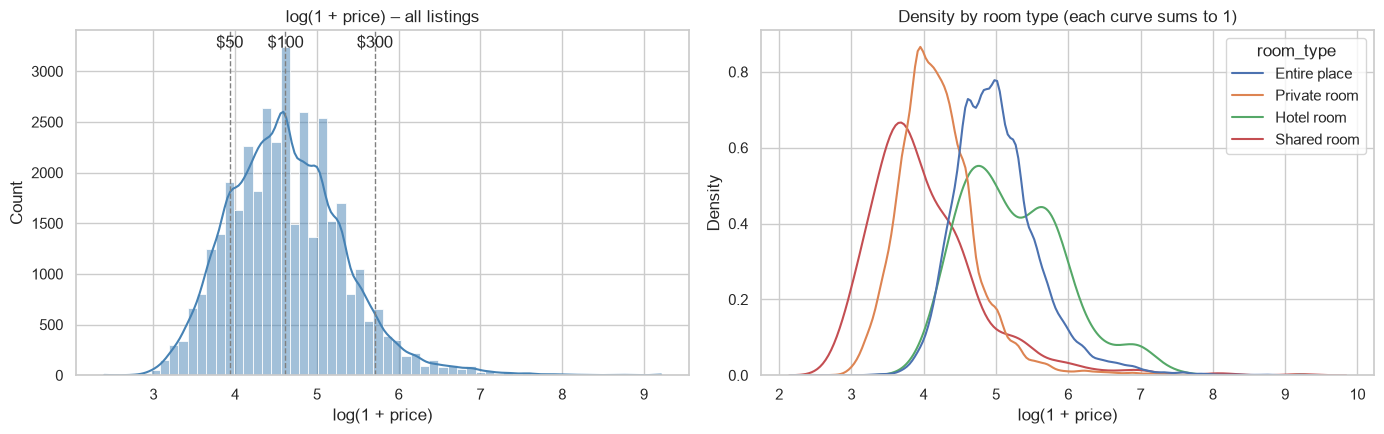

              median   std
room_type                 
Entire place    4.95  0.59
Hotel room      5.10  0.72
Private room    4.11  0.56
Shared room     3.83  0.78


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(pos["log_price"], bins=60, kde=True, ax=axes[0], color="steelblue")
axes[0].set(title="log(1 + price) – all listings", xlabel="log(1 + price)")
for x, lab in [(np.log1p(50), "$50"), (np.log1p(100), "$100"), (np.log1p(300), "$300")]:
    axes[0].axvline(x, color="grey", ls="--", lw=1); axes[0].text(x, axes[0].get_ylim()[1] * 0.95, lab, ha="center")
sns.kdeplot(data=pos, x="log_price", hue=pos["room_type"].astype(str), common_norm=False, ax=axes[1])
axes[1].set(title="Density by room type (each curve sums to 1)", xlabel="log(1 + price)")
plt.tight_layout(); save(fig, "01_price_distribution"); plt.show()

print(pos.groupby(pos["room_type"].astype(str))["log_price"].agg(["median", "std"]).round(2))

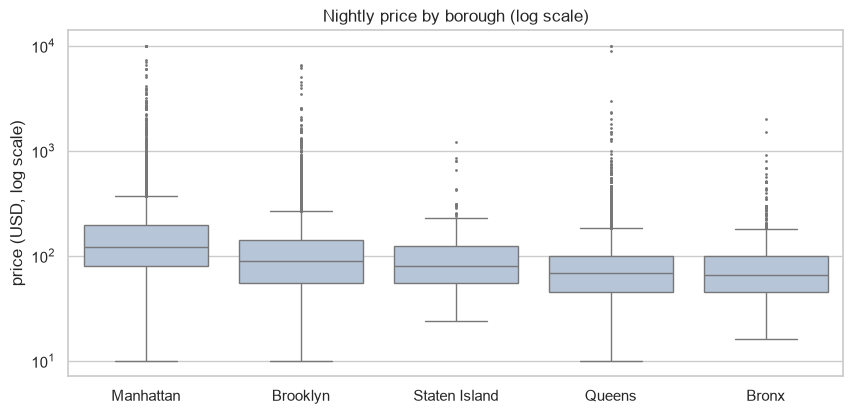

,0.25,0.5,0.75,n_above_q3+1.5IQR
district,,,,
Bronx,45.0,65.0,100.0,81
Brooklyn,55.0,89.0,140.0,763
Manhattan,79.0,120.0,195.0,1094
Queens,45.0,69.0,100.0,374
Staten Island,55.0,80.0,125.0,19


In [5]:
order = pos.groupby("district", observed=True)[TARGET].median().sort_values(ascending=False).index.astype(str)
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=pos, x=pos["district"].astype(str), y=TARGET, order=order, ax=ax, fliersize=1, color="lightsteelblue")
ax.set_yscale("log"); ax.set(title="Nightly price by borough (log scale)", xlabel="", ylabel="price (USD, log scale)")
save(fig, "02_price_by_borough"); plt.show()

iqr = pos.groupby("district", observed=True)[TARGET].quantile([.25, .5, .75]).unstack().round(0)
iqr["n_above_q3+1.5IQR"] = pos.groupby("district", observed=True)[TARGET].apply(
    lambda s: int((s > s.quantile(.75) + 1.5 * (s.quantile(.75) - s.quantile(.25))).sum()))
iqr

**Dataset story – A. The target**
- On the log scale the price is close to bell-shaped around **$100** (median 99, middle half $60–151, 95th percentile $349); the raw scale is dominated by a long right tail up to $10,000.
- **Room types form separate price levels:** typical log price 4.95 for entire places (≈ $140), 4.11 for private rooms (≈ $60), 3.83 for shared rooms (≈ $45); hotel rooms (5.10) show a second peak at higher prices.
- **Borough medians (descriptive, room types mixed):** Manhattan $120 (n = 16,528), Brooklyn $89 (n = 14,472), Staten Island $80 (n = 289), Queens $69 (n = 4,704), Bronx $65 (n = 991).
- The IQR rule applied on the raw scale within each borough flags **2,331 listings** as high outliers (Manhattan 1,094, Brooklyn 763). Whether a listing counts as an outlier depends on the scale (raw vs. log), so the S7 decision must be made on the scale the model uses.

## B. Categorical variables and price

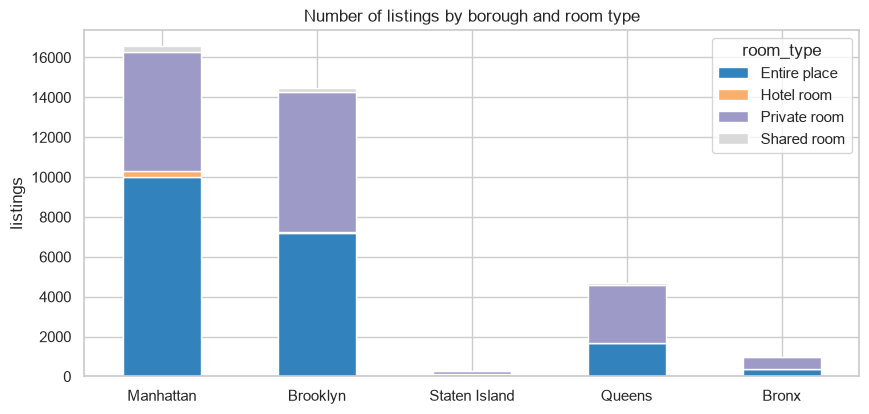

room_type,Entire place,Hotel room,Private room,Shared room
district,,,,
Manhattan,60.5,1.6,36.1,1.8
Brooklyn,49.8,0.1,48.5,1.6
Staten Island,50.9,0.0,48.1,1.0
Queens,35.3,0.2,61.7,2.8
Bronx,37.1,0.1,59.7,3.1


In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ct = pd.crosstab(df["district"].astype(str), df["room_type"].astype(str)).loc[order]
ct.plot(kind="bar", stacked=True, ax=ax, colormap="tab20c", edgecolor="white")
ax.set(title="Number of listings by borough and room type", xlabel="", ylabel="listings"); ax.tick_params(axis="x", rotation=0)
save(fig, "03_listings_by_borough_roomtype"); plt.show()
(ct.div(ct.sum(axis=1), axis=0) * 100).round(1)

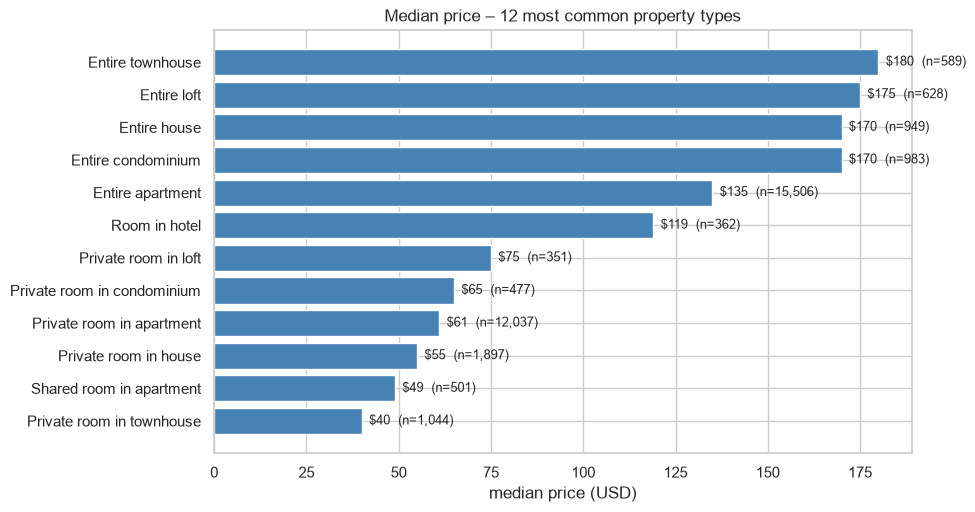

In [7]:
top_types = pos["property_type"].astype(str).value_counts().head(12).index
pt = (pos[pos["property_type"].astype(str).isin(top_types)]
        .groupby(pos["property_type"].astype(str))[TARGET].agg(n="size", median="median")
        .sort_values("median"))
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(pt.index, pt["median"], color="steelblue")
for i, (m, n) in enumerate(zip(pt["median"], pt["n"])):
    ax.text(m + 2, i, f"${m:.0f}  (n={n:,})", va="center", fontsize=9)
ax.set(title="Median price – 12 most common property types", xlabel="median price (USD)")
save(fig, "04_price_by_property_type"); plt.show()

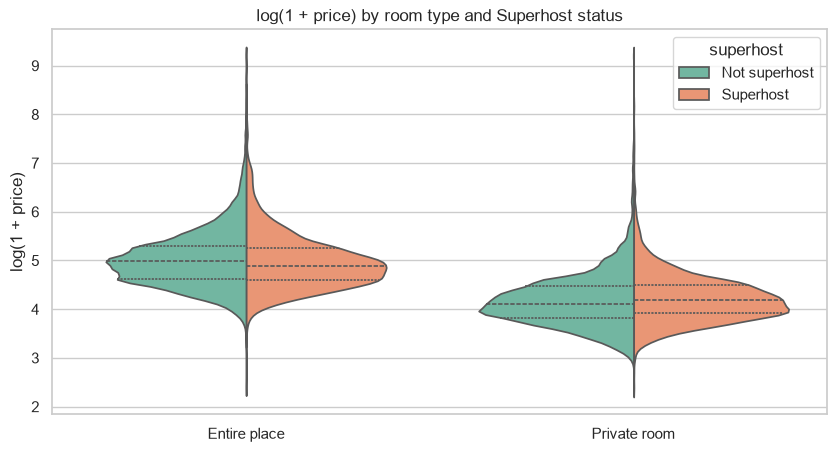

superhost,Not superhost,Superhost
room_type,,
Entire place,145.0,131.0
Private room,60.0,65.0


In [8]:
vio = pos[pos["room_type"].isin(["Entire place", "Private room"]) & pos["superhost"].notna()]
fig, ax = plt.subplots(figsize=(10, 5))
sns.violinplot(data=vio, x=vio["room_type"].astype(str), y="log_price", hue="superhost",
               split=True, inner="quartile", ax=ax, palette="Set2")
ax.set(title="log(1 + price) by room type and Superhost status", xlabel="", ylabel="log(1 + price)")
save(fig, "05_violin_roomtype_superhost"); plt.show()

vio.groupby([vio["room_type"].astype(str), "superhost"])[TARGET].median().unstack()

**Dataset story – B. Categories**
- **The room mix differs by borough:** 60.5% of Manhattan listings are entire places, while about 60% of Queens and Bronx listings are private rooms. Part of the borough price gap is therefore a room-type effect → S6 should compare boroughs **within** a room type.
- **Property type adds detail:** entire townhouses ($180), lofts ($175), houses and condominiums ($170) cost more than entire apartments ($135); private rooms range from $40 (townhouse) to $75 (loft).
- **Superhosts do not simply charge more:** for entire places Superhosts have a *lower* median ($131 vs $145), for private rooms a slightly higher one ($65 vs $60). A candidate hypothesis for S6.

## C. Numeric variables: correlation and scatter matrix
Spearman correlation (rank-based) is used because most variables are skewed. Review variables are included **for exploration only**.

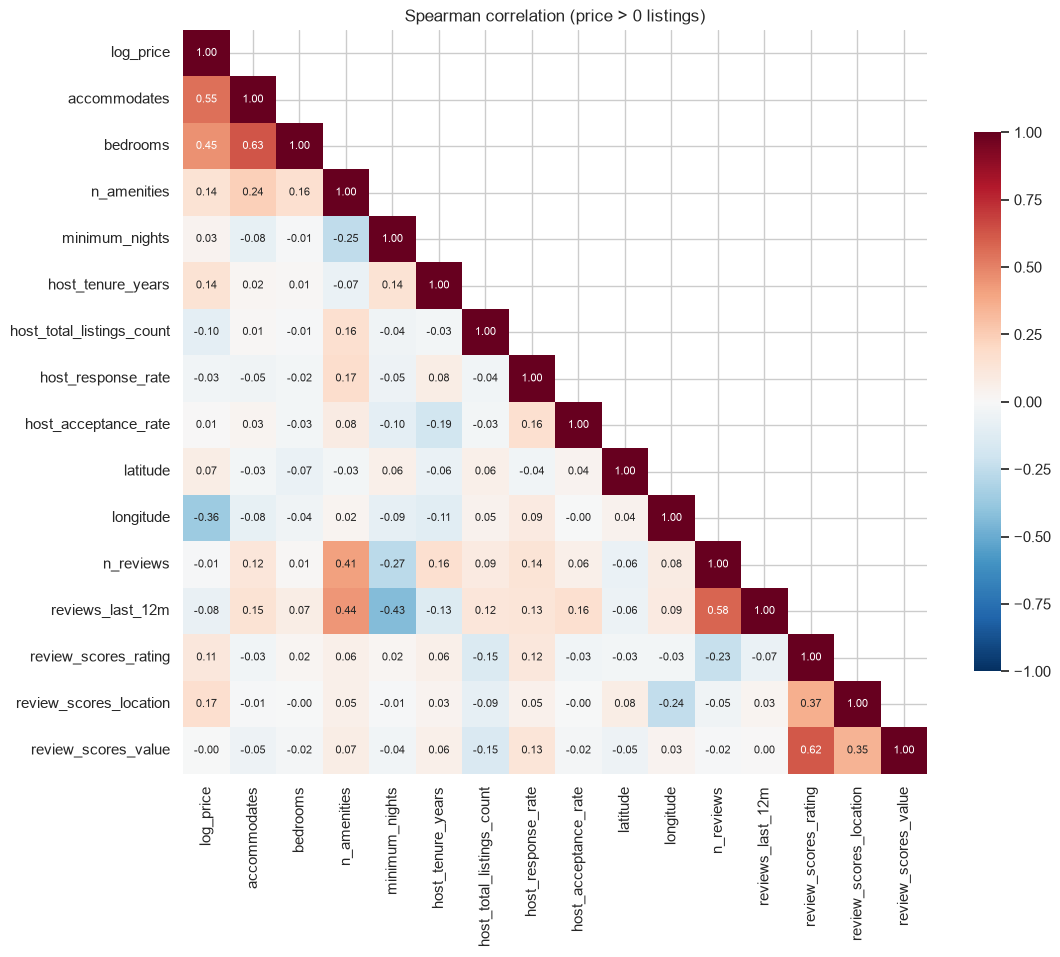

,rho with log_price
accommodates,0.554
bedrooms,0.455
longitude,-0.364
review_scores_location,0.168
n_amenities,0.143
host_tenure_years,0.143
review_scores_rating,0.111
host_total_listings_count,-0.095
reviews_last_12m,-0.076
latitude,0.074


In [9]:
num_vars = ["log_price", "accommodates", "bedrooms", "n_amenities", "minimum_nights", "host_tenure_years",
            "host_total_listings_count", "host_response_rate", "host_acceptance_rate", "latitude", "longitude",
            "n_reviews", "reviews_last_12m", "review_scores_rating", "review_scores_location", "review_scores_value"]
corr = pos[num_vars].corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 8}, square=True, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Spearman correlation (price > 0 listings)")
save(fig, "06_correlation_heatmap"); plt.show()

corr["log_price"].drop("log_price").sort_values(key=abs, ascending=False).round(3).to_frame("rho with log_price")

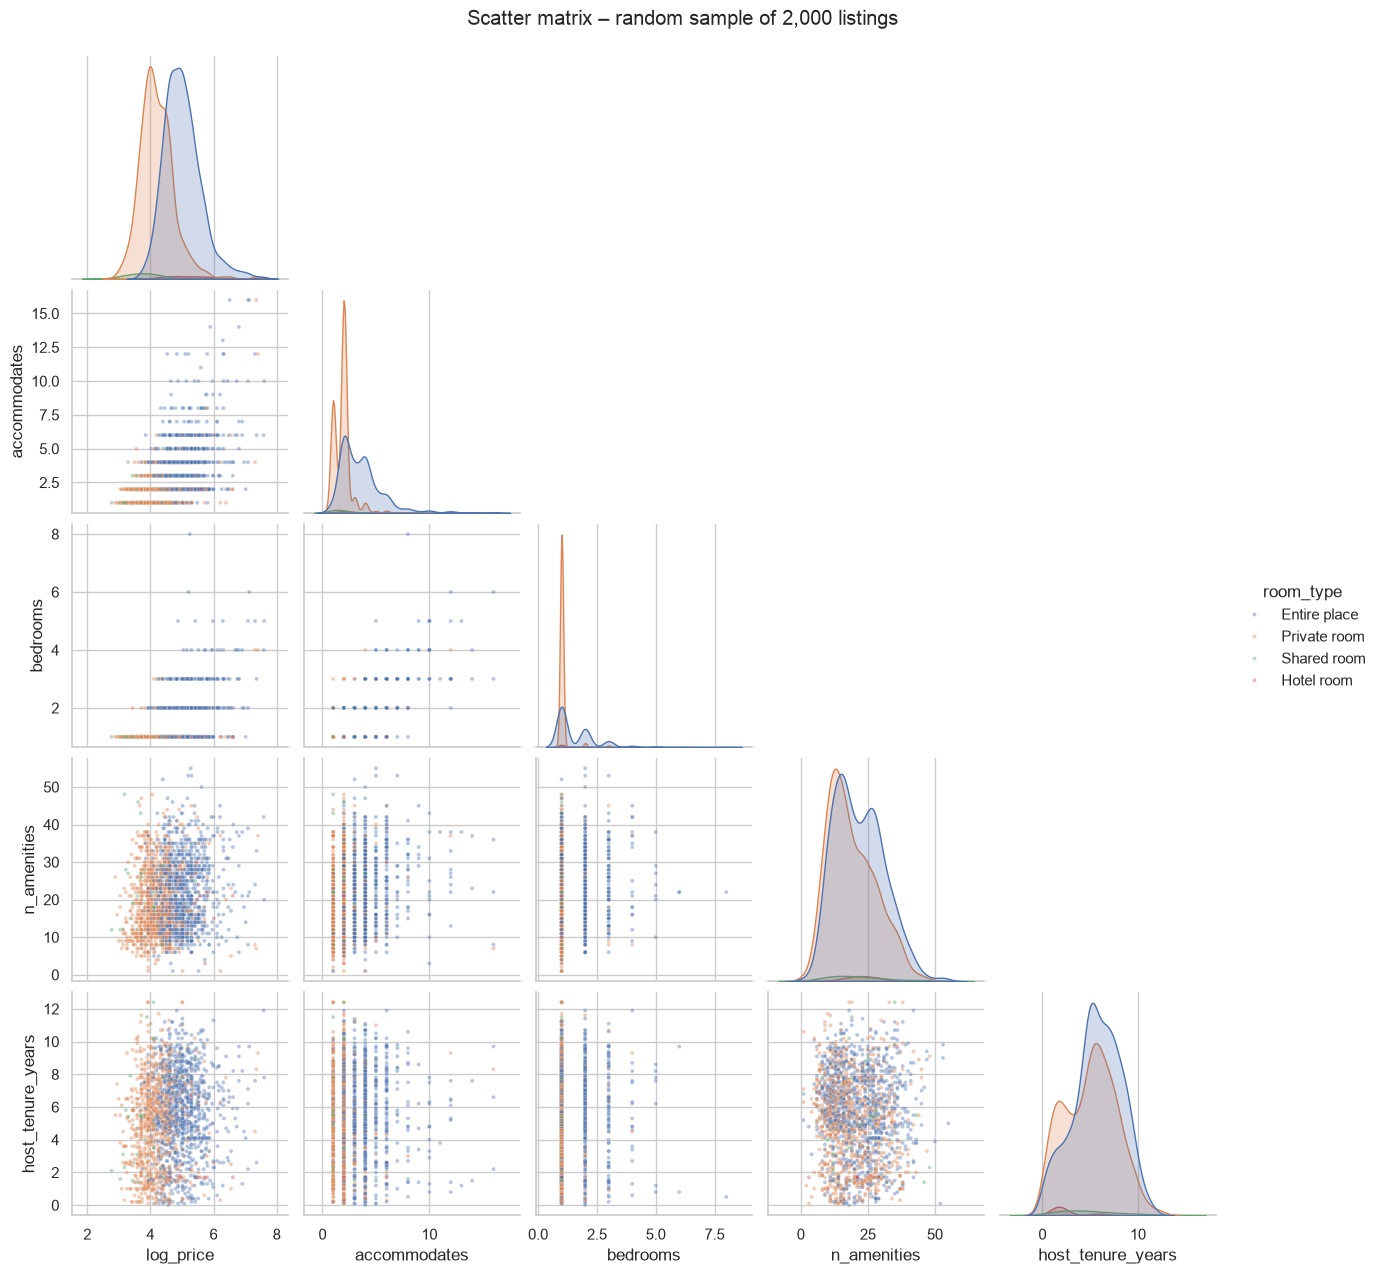

In [10]:
sample = pos.sample(2000, random_state=RANDOM_STATE)
g = sns.pairplot(sample, vars=["log_price", "accommodates", "bedrooms", "n_amenities", "host_tenure_years"],
                 hue="room_type", hue_order=["Entire place", "Private room", "Shared room", "Hotel room"],
                 corner=True, plot_kws={"s": 8, "alpha": .4}, diag_kind="kde")
g.figure.suptitle("Scatter matrix – random sample of 2,000 listings", y=1.02)
g.figure.savefig(FIG_DIR / "05_07_scatter_matrix.png", dpi=110, bbox_inches="tight"); plt.show()

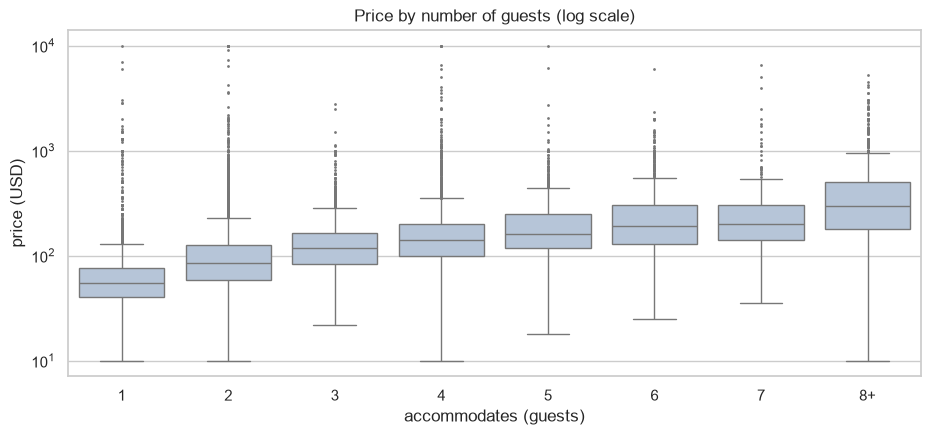

,n,median
guests,,
1,6229,55.0
2,16827,85.0
3,3820,119.0
4,5587,140.0
5,1499,160.0
6,1719,190.0
7,320,200.0
8+,983,299.0


In [11]:
guests = pos.assign(guests=pos["accommodates"].clip(upper=8).astype(int).astype(str).replace({"8": "8+"}))
guest_order = [str(i) for i in range(0, 8)] + ["8+"]
guest_order = [g_ for g_ in guest_order if g_ in set(guests["guests"])]
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=guests, x="guests", y=TARGET, order=guest_order, ax=ax, fliersize=1, color="lightsteelblue")
ax.set_yscale("log"); ax.set(title="Price by number of guests (log scale)", xlabel="accommodates (guests)", ylabel="price (USD)")
save(fig, "08_price_by_guests"); plt.show()
guests.groupby("guests")[TARGET].agg(n="size", median="median").reindex(guest_order)

**Dataset story – C. Numeric relations**
- The strongest monotonic links with log price are **size** (accommodates ρ = 0.55, bedrooms ρ = 0.45) and **location** (longitude ρ = −0.36: the further east, the cheaper).
- Amenity count and host tenure have weak positive links (ρ = 0.14); minimum nights, host response and acceptance rates are close to 0.
- Review variables (exploration only) are weak: location score ρ = 0.17, overall rating 0.11, value score ≈ 0.
- **Collinearity to remember for the linear models (S9):** accommodates–bedrooms ρ = 0.63, rating–value score 0.62, total reviews–reviews in the last year 0.58.
- Price rises steadily with capacity: 1 guest $55, 2 guests $85, 4 guests $140, 6 guests $190, 8+ guests $299.

## D. Location

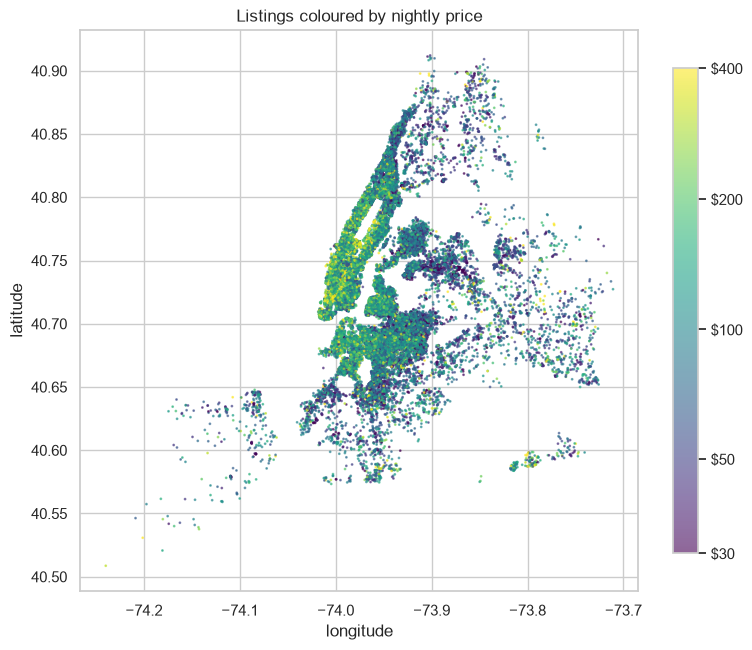

Spearman rho(distance to Times Square, log_price): -0.346


,n,median
"(0, 2]",4732,141.5
"(2, 5]",8500,130.0
"(5, 10]",15984,85.0
"(10, 20]",7149,71.0
"(20, 60]",619,90.0


In [12]:
fig, ax = plt.subplots(figsize=(9, 9))
pts = ax.scatter(pos["longitude"], pos["latitude"], c=pos["log_price"], s=1, cmap="viridis",
                 vmin=np.log1p(30), vmax=np.log1p(400), alpha=.6)
ax.set_aspect(1 / np.cos(np.deg2rad(40.7)))
cb = fig.colorbar(pts, ax=ax, shrink=.7)
ticks = [30, 50, 100, 200, 400]; cb.set_ticks(np.log1p(ticks)); cb.set_ticklabels([f"${t}" for t in ticks])
ax.set(title="Listings coloured by nightly price", xlabel="longitude", ylabel="latitude")
save(fig, "09_price_map"); plt.show()

# Distance to Times Square as a simple location summary (EDA only)
TS = (40.7580, -73.9855)
km = np.sqrt(((pos["latitude"] - TS[0]) * 111) ** 2 + ((pos["longitude"] - TS[1]) * 111 * np.cos(np.deg2rad(40.7))) ** 2)
pos["km_to_times_sq"] = km
print("Spearman rho(distance to Times Square, log_price):", round(pos[["km_to_times_sq", "log_price"]].corr("spearman").iloc[0, 1], 3))
pos.groupby(pd.cut(km, [0, 2, 5, 10, 20, 60]), observed=True)[TARGET].agg(n="size", median="median")

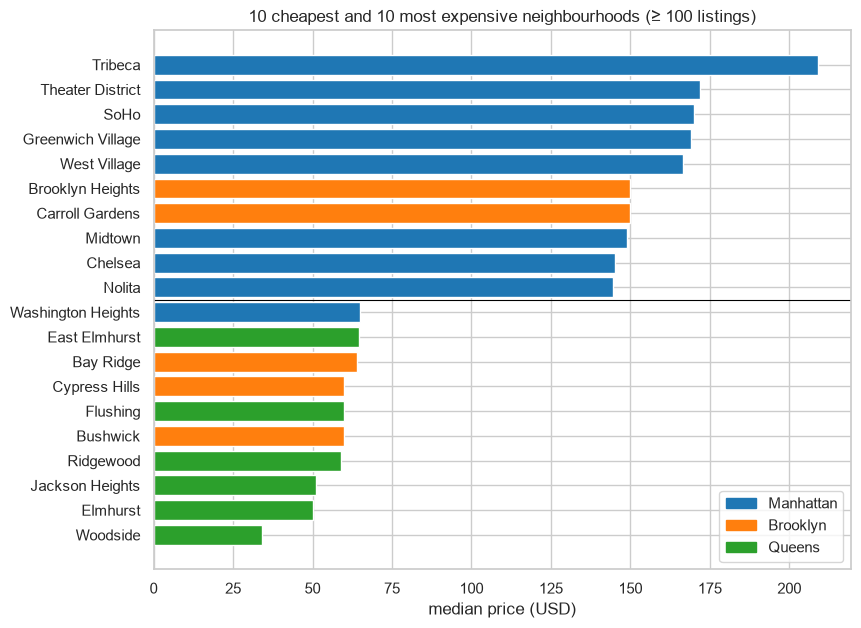

,n,median,borough
neighbourhood,,,
Woodside,363,34.0,Queens
Elmhurst,241,50.0,Queens
Jackson Heights,213,51.0,Queens
Ridgewood,291,59.0,Queens
Bushwick,1678,60.0,Brooklyn
Flushing,352,60.0,Queens
Cypress Hills,104,60.0,Brooklyn
Bay Ridge,119,64.0,Brooklyn
East Elmhurst,146,64.5,Queens


In [13]:
nb = (pos.groupby(pos["neighbourhood"].astype(str))
         .agg(n=(TARGET, "size"), median=(TARGET, "median"), borough=("district", lambda s: str(s.iloc[0]))))
nb = nb[nb["n"] >= 100].sort_values("median")
show = pd.concat([nb.head(10), nb.tail(10)])
colors = show["borough"].map({"Manhattan": "#1f77b4", "Brooklyn": "#ff7f0e", "Queens": "#2ca02c",
                              "Bronx": "#d62728", "Staten Island": "#9467bd"})
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(show.index, show["median"], color=colors)
ax.axhline(9.5, color="black", lw=.8)
palette = {"Manhattan": "#1f77b4", "Brooklyn": "#ff7f0e", "Queens": "#2ca02c", "Bronx": "#d62728", "Staten Island": "#9467bd"}
present = [b for b in palette if b in set(show["borough"])]           # legend only for boroughs shown
ax.legend([plt.Rectangle((0, 0), 1, 1, color=palette[b]) for b in present], present, loc="lower right")
ax.set(title="10 cheapest and 10 most expensive neighbourhoods (≥ 100 listings)", xlabel="median price (USD)")
save(fig, "10_neighbourhood_extremes"); plt.show()
show

**Dataset story – D. Location**
- The map shows a clear gradient: lower and midtown Manhattan and the Brooklyn waterfront are the most expensive; eastern Queens and the Bronx the cheapest.
- Distance to Times Square: median $141.5 within 2 km, $130 at 2–5 km, $85 at 5–10 km, $71 at 10–20 km (Spearman ρ = −0.35). Beyond 20 km (619 listings in the outer edges of the city) the median rises again to $90.
- Of the 10 most expensive neighbourhoods 8 are in Manhattan and 2 in Brooklyn (Brooklyn Heights, Carroll Gardens); of the 10 cheapest 6 are in Queens, 3 in Brooklyn and 1 in Manhattan (Washington Heights).
- Location will matter for the model, but `neighbourhood` has 220 levels → its encoding is a Tier 2 decision in S7.

## E. Time

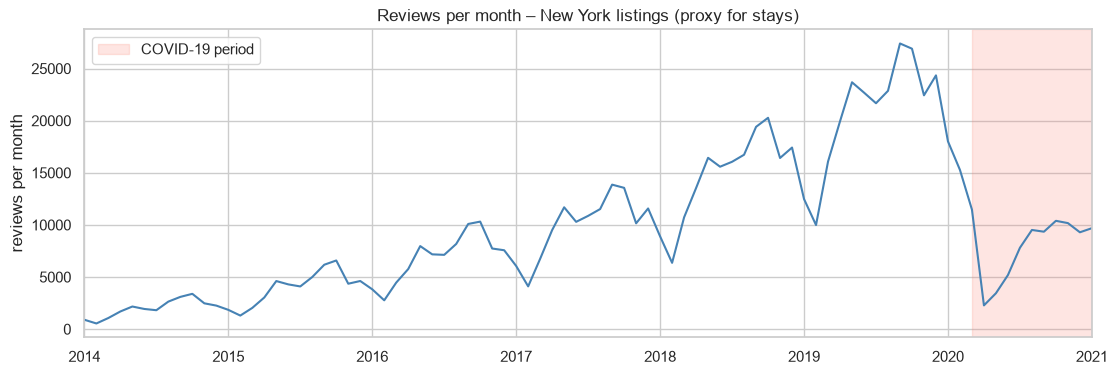

Reviews per year: {2015: 47962, 2016: 82958, 2017: 119926, 2018: 177846, 2019: 250469, 2020: 112173, 2021: 10110}
Seasonality 2015-2019 – busiest month: 10 | quietest month: 2


In [14]:
reviews = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "Reviews.csv", usecols=["listing_id", "date"],
                      encoding="latin-1", parse_dates=["date"])
ny_rev = reviews[reviews["listing_id"].isin(df["listing_id"])]
monthly = ny_rev.set_index("date").resample("MS").size().loc["2014-01-01":"2021-01-01"]

fig, ax = plt.subplots(figsize=(13, 4))
monthly.plot(ax=ax, color="steelblue")
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-01-01"), color="salmon", alpha=.2, label="COVID-19 period")
ax.set(title="Reviews per month – New York listings (proxy for stays)", xlabel="", ylabel="reviews per month"); ax.legend()
save(fig, "11_reviews_per_month"); plt.show()

by_year = ny_rev.groupby(ny_rev["date"].dt.year).size()
by_month = ny_rev[ny_rev["date"].dt.year.between(2015, 2019)].groupby(ny_rev["date"].dt.month).size()
print("Reviews per year:", by_year.loc[2015:2021].to_dict())
print("Seasonality 2015-2019 – busiest month:", by_month.idxmax(), "| quietest month:", by_month.idxmin())

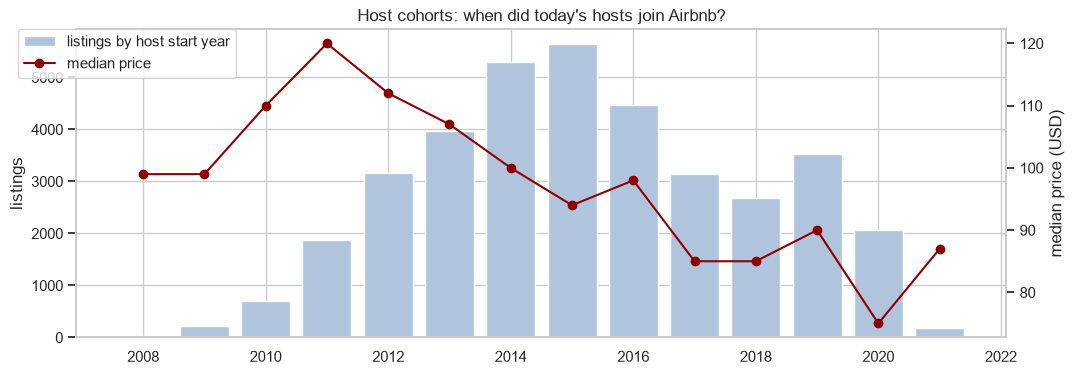

,listings,median_price,superhost_share
host_since,,,
2008.0,25,99.0,0.64
2009.0,226,99.0,0.248
2010.0,694,110.0,0.265
2011.0,1872,120.0,0.239
2012.0,3167,112.0,0.201
2013.0,3973,107.0,0.188
2014.0,5300,100.0,0.168
2015.0,5639,94.0,0.165
2016.0,4468,98.0,0.208


In [15]:
cohort = (pos.dropna(subset=["host_since"])
             .groupby(pos["host_since"].dt.year)
             .agg(listings=(TARGET, "size"), median_price=(TARGET, "median"),
                  superhost_share=("host_is_superhost", "mean")))
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.bar(cohort.index, cohort["listings"], color="lightsteelblue", label="listings by host start year")
ax1.set_ylabel("listings")
ax2 = ax1.twinx(); ax2.plot(cohort.index, cohort["median_price"], color="darkred", marker="o", label="median price")
ax2.set_ylabel("median price (USD)"); ax2.grid(False)
ax1.set_title("Host cohorts: when did today's hosts join Airbnb?")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.9))
save(fig, "12_host_cohorts"); plt.show()
cohort.round(3)

**Dataset story – E. Time**
- Review activity grew every year until 2020: 48k reviews in 2015 → 250k in 2019, with a seasonal pattern (2015–2019: busiest month October, quietest February).
- Monthly reviews peaked at about 27k in autumn 2019, fell to about 2.3k in April 2020 and recovered only to 9–10k per month by late 2020; 2020 had 112k reviews, 55% fewer than 2019. The timing is consistent with the COVID-19 disruption, although this data alone cannot prove the cause.
- **Host cohorts:** most listings belong to hosts who joined in 2013–2016 (peak 2015: 5,639 listings). Listings of longer-standing hosts are priced higher: median $120 for the 2011 cohort vs $75 for hosts who joined in 2020. This is a cross-sectional comparison; it does not show that tenure itself raises prices.

## F. Missing data patterns
The nullity heatmap shows how strongly missingness of two columns goes together (1 = always missing together).

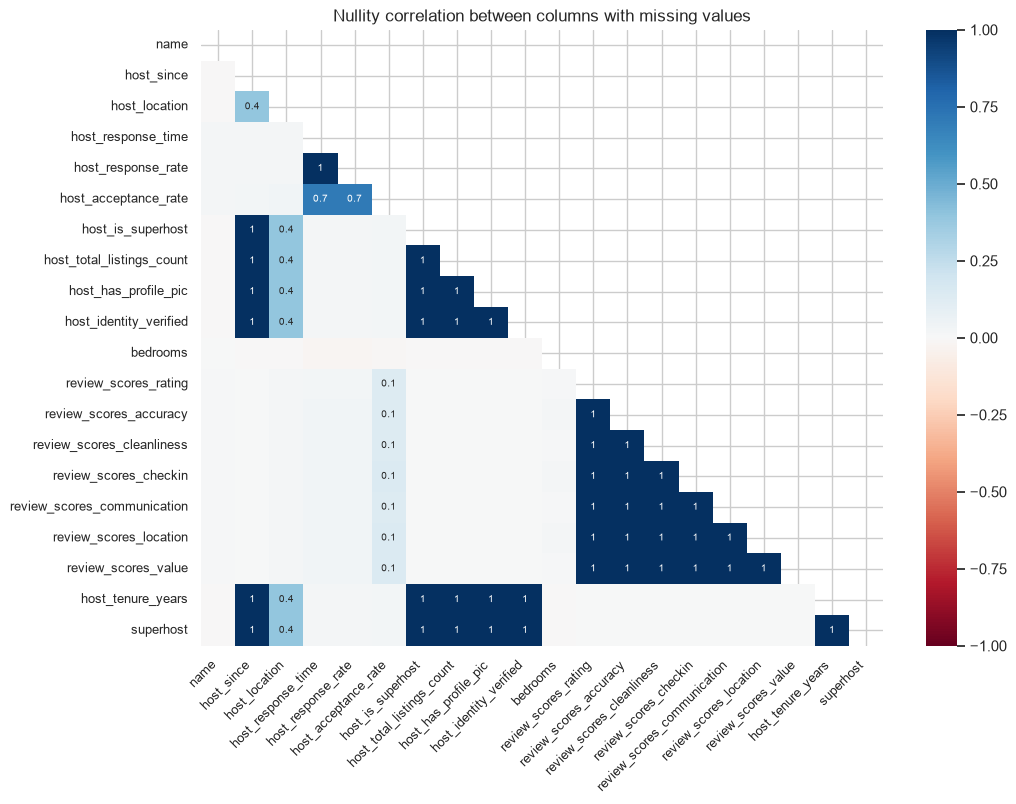

acceptance rate missing,False,True
response rate missing,,
False,17572,933
True,4807,13700


In [16]:
miss_cols = [c for c in df.columns if df[c].isna().any() and c not in ["first_review", "last_review"]]
ax = msno.heatmap(df[miss_cols], figsize=(11, 8), fontsize=9)
ax.set_title("Nullity correlation between columns with missing values")
ax.get_figure().savefig(FIG_DIR / "05_13_missing_heatmap.png", dpi=110, bbox_inches="tight"); plt.show()

pd.crosstab(df["host_response_rate"].isna(), df["host_acceptance_rate"].isna(),
            rownames=["response rate missing"], colnames=["acceptance rate missing"])

**Dataset story – F. Missing data**
Missingness forms three separate groups, which supports group-wise treatment in S7:
1. **Host profile:** `host_since`, `host_is_superhost` and three other host fields are missing in the same 18 rows (nullity correlation 1).
2. **Host activity:** response time and response rate are always missing together; acceptance rate is strongly linked to them (0.7). 13,700 listings miss both rates, 4,807 only the response rate, 933 only the acceptance rate.
3. **Review scores:** the 7 scores are missing together and almost independently of the other groups (structural: no reviews).
- `bedrooms` missingness is unrelated to all other columns, so the studio hypothesis must be checked through the values themselves (property type, guests, listing names).

## G. Amenities and price
To limit confounding by room type, the comparison uses **entire places only**: median price of listings with vs. without each amenity. This is an association, not a causal effect.

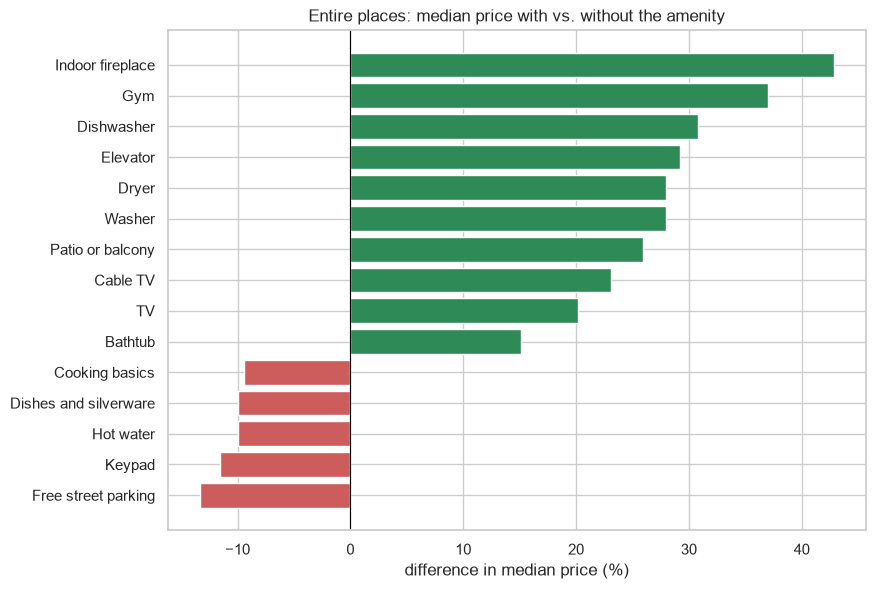

Amenities tested (5-90% prevalence): 44


,amenity,share,median_with,median_without,ratio
20,Free street parking,0.368,130.0,150.0,0.867
42,Keypad,0.053,126.5,143.0,0.885
8,Hot water,0.602,135.0,150.0,0.900
9,Dishes and silverware,0.510,135.0,150.0,0.900
13,Cooking basics,0.461,135.0,149.0,0.906
29,Bathtub,0.142,160.0,139.0,1.151
1,TV,0.801,149.0,124.0,1.202
23,Cable TV,0.291,160.0,130.0,1.231
31,Patio or balcony,0.110,175.0,139.0,1.259
11,Washer,0.475,160.0,125.0,1.280


In [17]:
ent = pos[pos["room_type"] == "Entire place"].copy()
ent_lists = ent["amenities"].map(parse_amenities)
counts = pd.Series([a for lst in ent_lists for a in set(lst)]).value_counts()
candidates = counts[(counts / len(ent)).between(0.05, 0.90)].index

rows = []
for a in candidates:
    has = ent_lists.map(lambda lst: a in lst)
    rows.append({"amenity": a, "share": has.mean(),
                 "median_with": ent.loc[has, TARGET].median(), "median_without": ent.loc[~has, TARGET].median()})
prem = pd.DataFrame(rows)
prem["ratio"] = prem["median_with"] / prem["median_without"]
show = pd.concat([prem.nlargest(10, "ratio"), prem.nsmallest(5, "ratio")]).sort_values("ratio")

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(show["amenity"], (show["ratio"] - 1) * 100, color=np.where(show["ratio"] >= 1, "seagreen", "indianred"))
ax.axvline(0, color="black", lw=.8)
ax.set(title="Entire places: median price with vs. without the amenity", xlabel="difference in median price (%)")
save(fig, "14_amenity_premium"); plt.show()
print("Amenities tested (5-90% prevalence):", len(candidates))
show.round(3)

**Dataset story – G. Amenities (entire places, 44 amenities with 5–90% prevalence)**
- Amenities typical of larger or upscale buildings go with higher prices: indoor fireplace +43%, gym +37%, dishwasher +31%, elevator +29%, washer and dryer +28%, patio or balcony +26%.
- Basic kitchen items, hot water, keypads and **free street parking** go with 9–13% lower prices. Street parking points to outer-borough houses, so this is a **location effect**, not an amenity effect.
- Amenity indicators look useful as features (a Tier 2 decision in S7), but these differences are associations, not causal effects.

## H. Superhost status (S11 target)

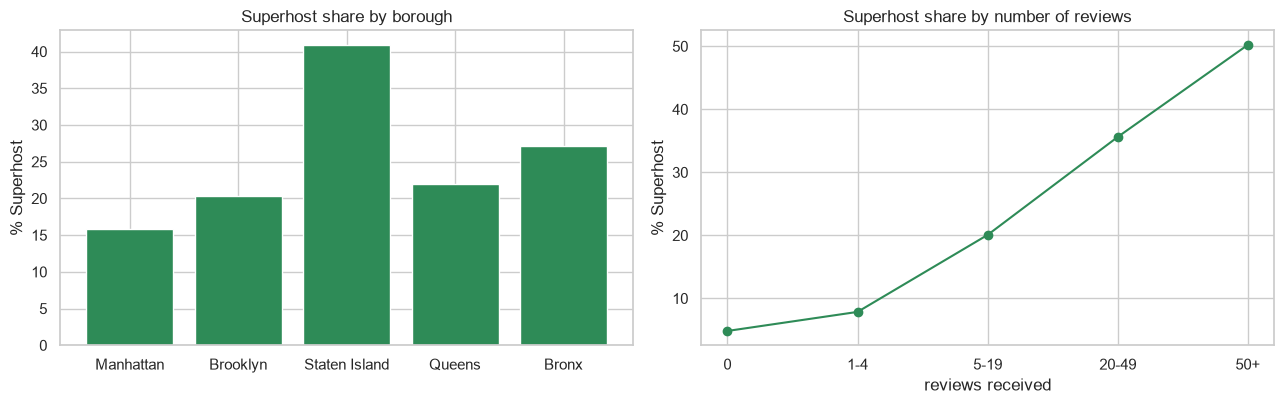

{'Manhattan': 0.158, 'Brooklyn': 0.203, 'Staten Island': 0.408, 'Queens': 0.22, 'Bronx': 0.271}
{'0': 0.048, '1-4': 0.079, '5-19': 0.201, '20-49': 0.356, '50+': 0.502}


In [18]:
sh = df[df["host_is_superhost"].notna()].copy()
sh["review_band"] = pd.cut(sh["n_reviews"], [-1, 0, 4, 19, 49, 10_000], labels=["0", "1-4", "5-19", "20-49", "50+"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
by_borough = sh.groupby(sh["district"].astype(str))["host_is_superhost"].mean().loc[order]
axes[0].bar(by_borough.index, by_borough * 100, color="seagreen")
axes[0].set(title="Superhost share by borough", ylabel="% Superhost")
by_band = sh.groupby("review_band", observed=True)["host_is_superhost"].mean()
axes[1].plot(by_band.index.astype(str), by_band * 100, marker="o", color="seagreen")
axes[1].set(title="Superhost share by number of reviews", xlabel="reviews received", ylabel="% Superhost")
plt.tight_layout(); save(fig, "15_superhost"); plt.show()
print(by_borough.round(3).to_dict()); print(by_band.round(3).to_dict())

**Dataset story – H. Superhost status (S11 target)**
- The Superhost share is lowest in Manhattan (16%, n = 16,545) and highest on Staten Island (41%, n = 289; Wilson CI 35–47%, see block I); Brooklyn 20%, Queens 22%, Bronx 27%.
- It rises sharply with experience: 4.8% for listings without reviews, 7.9% with 1–4 reviews, 20% with 5–19, 36% with 20–49 and **50% with 50+ reviews**.
- This matches Airbnb's own Superhost rules (a minimum number of stays and high ratings) and confirms the two-feature-set design for S11 (D6).

## I. Stratified views with sample sizes and confidence intervals (added after review)
The reviewer (REVIEW #5) asked for (1) price by room type **within** each borough, (2) price by capacity **within entire places**, and (3) sample sizes and confidence intervals for small groups. Medians get a **bootstrap 95% CI** (1,000 resamples); shares get a **Wilson 95% CI**.

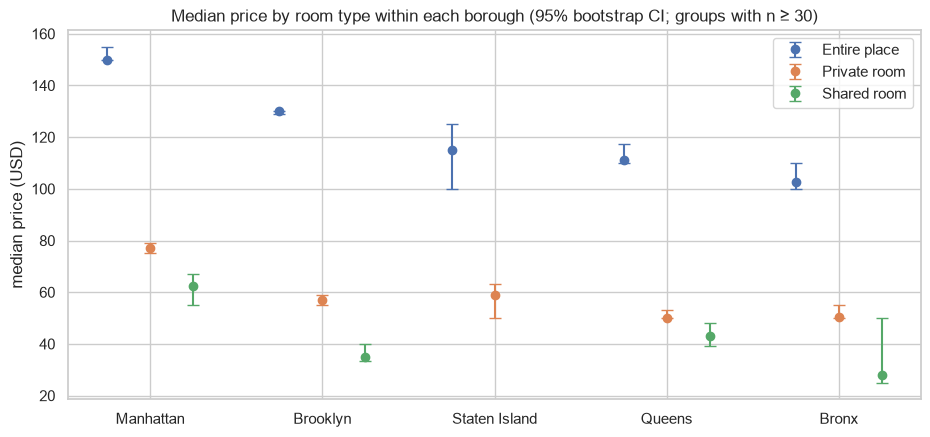

,borough,room_type,n,median,ci_low,ci_high
0,Bronx,Entire place,368,102.5,100.0,110.0
1,Bronx,Private room,592,50.5,50.0,55.0
2,Bronx,Shared room,31,28.0,25.0,50.0
3,Brooklyn,Entire place,7206,130.0,129.0,130.0
4,Brooklyn,Private room,7021,57.0,55.0,59.0
5,Brooklyn,Shared room,230,35.0,33.5,40.0
6,Manhattan,Entire place,10014,150.0,150.0,155.0
7,Manhattan,Hotel room,247,179.0,155.0,231.0
8,Manhattan,Private room,5975,77.0,75.0,79.0
9,Manhattan,Shared room,292,62.5,55.0,67.0


In [19]:
from statsmodels.stats.proportion import proportion_confint
rng = np.random.default_rng(RANDOM_STATE)

def median_ci(values, n_boot=1000):
    v = np.asarray(values)
    boots = np.median(rng.choice(v, size=(n_boot, v.size), replace=True), axis=1) if v.size <= 4000 else \
            np.array([np.median(rng.choice(v, size=v.size, replace=True)) for _ in range(n_boot)])
    return np.percentile(boots, [2.5, 97.5])

rows = []
for (b, r), g in pos.groupby([pos["district"].astype(str), pos["room_type"].astype(str)]):
    if len(g) < 30:            # too few listings for a stable estimate
        continue
    lo, hi = median_ci(g[TARGET].to_numpy())
    rows.append({"borough": b, "room_type": r, "n": len(g), "median": g[TARGET].median(), "ci_low": lo, "ci_high": hi})
br = pd.DataFrame(rows)
br.to_csv(TABLE_DIR / "05_price_borough_roomtype_ci.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 4.8))
rooms = ["Entire place", "Private room", "Shared room"]
for k, r in enumerate(rooms):
    sub = br[br["room_type"] == r].set_index("borough").reindex(list(order)).dropna()
    x = np.array([list(order).index(b) for b in sub.index]) + (k - 1) * 0.25   # keep boroughs aligned
    ax.errorbar(x, sub["median"], yerr=[sub["median"] - sub["ci_low"], sub["ci_high"] - sub["median"]],
                fmt="o", capsize=4, label=r)
    ax.set_xticks(np.arange(len(order))); ax.set_xticklabels(order)
ax.set(title="Median price by room type within each borough (95% bootstrap CI; groups with n ≥ 30)", ylabel="median price (USD)")
ax.legend(); save(fig, "16_price_roomtype_within_borough"); plt.show()
br.round(1)

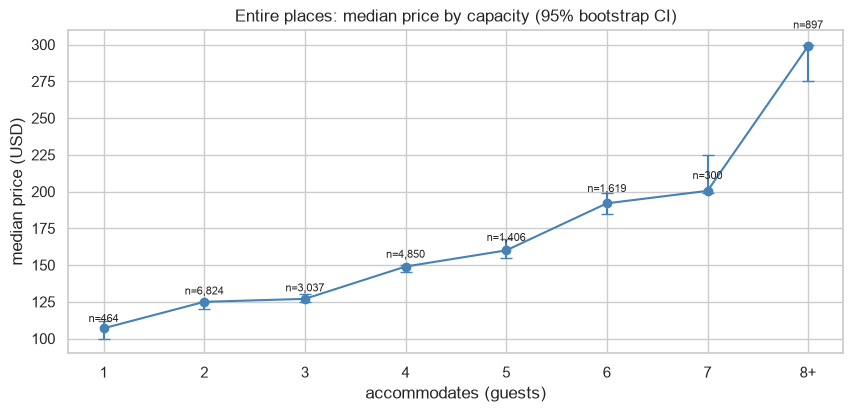

,guests,n,median,ci_low,ci_high
0,1,464,107.0,100.0,112.0
1,2,6824,125.0,120.0,125.0
2,3,3037,127.0,125.0,130.0
3,4,4850,149.0,145.0,150.0
4,5,1406,160.0,155.0,168.0
5,6,1619,192.0,185.0,199.0
6,7,300,200.5,199.0,225.0
7,8+,897,299.0,275.0,300.0


In [20]:
ent = pos[pos["room_type"] == "Entire place"]
cap = ent.assign(guests=ent["accommodates"].clip(upper=8).astype(int))
rows = []
for gval, g in cap.groupby("guests"):
    lo, hi = median_ci(g[TARGET].to_numpy())
    rows.append({"guests": "8+" if gval == 8 else str(gval), "n": len(g), "median": g[TARGET].median(), "ci_low": lo, "ci_high": hi})
cap_tab = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.errorbar(cap_tab["guests"], cap_tab["median"], yerr=[cap_tab["median"] - cap_tab["ci_low"], cap_tab["ci_high"] - cap_tab["median"]],
            fmt="o-", capsize=4, color="steelblue")
for x, y, n in zip(cap_tab["guests"], cap_tab["median"], cap_tab["n"]):
    ax.text(x, y * 1.04, f"n={n:,}", ha="center", fontsize=8)
ax.set(title="Entire places: median price by capacity (95% bootstrap CI)", xlabel="accommodates (guests)", ylabel="median price (USD)")
save(fig, "17_entire_price_by_capacity"); plt.show()
cap_tab.round(1)

In [21]:
sh_tab = (df[df["host_is_superhost"].notna()]
            .groupby(df["district"].astype(str))["host_is_superhost"]
            .agg(n="size", superhosts="sum"))
sh_tab["share"] = sh_tab["superhosts"] / sh_tab["n"]
ci = proportion_confint(sh_tab["superhosts"], sh_tab["n"], alpha=0.05, method="wilson")
sh_tab["ci_low"], sh_tab["ci_high"] = ci
sh_tab.loc[list(order)].round(3)

,n,superhosts,share,ci_low,ci_high
district,,,,,
Manhattan,16545,2609,0.158,0.152,0.163
Brooklyn,14468,2940,0.203,0.197,0.210
Staten Island,289,118,0.408,0.353,0.466
Queens,4700,1035,0.22,0.209,0.232
Bronx,992,269,0.271,0.244,0.300


**Dataset story – I. Stratified views (added after REVIEW #5)**
- **Room type matters in every borough.** An entire place costs about 2x a private room everywhere: Manhattan $150 vs $77, Brooklyn $130 vs $57, Queens $111 vs $50, Bronx $102.5 vs $50.5, Staten Island $115 vs $59 (all CIs narrow and non-overlapping).
- **The borough gap shrinks within a room type.** Among entire places the ranking is Manhattan $150 > Brooklyn $130 > Staten Island $115 > Queens $111 > Bronx $102.5: Manhattan is about 1.5x the Bronx, compared with 1.85x ($120 vs $65) when room types are mixed. Part of the raw borough gap is therefore room composition.
- **Capacity still raises price within entire places:** 1 guest $107 (n = 464), 2 guests $125 (n = 6,824), 4 guests $149, 6 guests $192, 8+ guests $299 (n = 897, CI $275–300).
- **The Staten Island Superhost share is stable despite the small group:** 40.8% (118 of 289, Wilson 95% CI 35.3–46.6%) vs Manhattan 15.8% (2,609 of 16,545, CI 15.2–16.3%).


## Evaluation of S5

**What we did:** 2 summary tables, 17 figures and a stratified table with confidence intervals saved in `reports/figures/05_*.png` (histogram/density, box, stacked bar, horizontal bars, violin, Spearman heatmap, scatter matrix, map, line charts, nullity heatmap), each block closed with a dataset story.

**Main findings**
1. Price is driven mainly by **room type, size and location**; on the log scale the target is well-behaved.
2. Borough differences are partly a **room-mix effect** → comparisons must be made within room type.
3. Missing data comes in **three independent groups** (host profile, host activity, review scores) plus an isolated `bedrooms` gap.
4. COVID cut review activity by more than half; the snapshot describes a disrupted, long-stay-dominated market.
5. Superhost status rises strongly with review count and is more common outside Manhattan.

**Association, prediction and causation.** Everything in this notebook is an **association** in a historical snapshot. Associations can still help **prediction** (S9–S11), but none of them shows a **causal** effect: e.g. a gym does not necessarily raise the price, and becoming a Superhost does not necessarily change it.

**Review (REVIEW #5, ChatGPT):** approved with changes. Applied: stratified views (block I), sample sizes and confidence intervals for small groups, and more careful wording on COVID, host cohorts and amenities.

**Implications for later stages**
- **S6 hypothesis candidates:** (1) entire place vs. private room price, (2) price differences between boroughs within entire places, (3) Superhost share differs between Manhattan and the other boroughs, (4) Superhost vs. non-Superhost price within entire places, (5) monotonic link between capacity and price.
- **S7:** outlier rules on the log scale; group-wise missing-data handling; encoding for 220 neighbourhoods; amenity indicators; the 18-row host gap.
- **S9:** collinearity (accommodates–bedrooms) favours Ridge/Lasso/PCR comparisons.

**Decisions:** Tier 1 only (chart types and styling). No data was changed.

**Next step:** S6 – statistics: choose 3–5 hypotheses and tests with assumption checks (Tier 2 → CONSULT with ChatGPT before running them).